part A
task 1

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset
housing = fetch_california_housing(as_frame=True)

# Convert the dataset into a DataFrame
df = housing.frame.copy()

# Display the first five rows
df.head()
#The dataset contains information about California housing districts.
 #It has 20,640 observations and eight input features. The target, MedHouseVal,represents median house value in units of $100,000.


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


task 2

In [31]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names, data types, and non-null counts
df.info()

# Display basic statistical information
df.describe()
#The shape should be (20640, 9), including eight independent features and one target column.
#The info() method shows the data types and non-null counts, while describe() summarizes numerical columns.

Dataset Shape: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


task 3

In [32]:
# Count missing values in each column
print(df.isnull().sum())

# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())
#The California Housing dataset has no missing values in its original form.
#Checking this is important because missing data can affect model training and may require cleaning before fitting a model.

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Total Missing Values: 0


task 4

In [33]:
# Independent variables
X = df.drop("MedHouseVal", axis=1)

# Dependent variable
y = df["MedHouseVal"]

print("Independent Features (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)
#X contains eight independent features, such as median income, house age, average rooms, population, latitude, and longitude.
#y contains MedHouseVal, the numerical value the model must predict.

Independent Features (X):
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Target Variable (y):
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

X Shape: (20640, 8)
y Shape: (20640,)


task 5

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)
#The training set contains 16,512 samples, and the testing set contains 4,128 samples. The model learns from the training data and is evaluated on the separate testing data. random_state=42 makes the split reproducible.

Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


task 6

In [35]:
# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")
#The LinearRegression() model learns a linear relationship between the eight independent features and median house value. The fit() method estimates the coefficients using the training data.

Linear Regression model trained successfully!


task 7

In [36]:
# Predict values for the test dataset
y_pred = model.predict(X_test)

print("First 10 Predicted Values:")
print(y_pred[:10])
#The model uses the features in X_test to estimate house values. These predictions will be compared with the actual values in y_test to measure performance.

First 10 Predicted Values:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


task 8 to 11

In [37]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R² Score:", round(r2, 4))


Mean Absolute Error (MAE): 0.5332
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R² Score: 0.5758


task 12

In [38]:
# Compare actual and predicted values for the first 10 test samples
comparison = pd.DataFrame({
    "Actual Value": y_test.iloc[:10].values,
    "Predicted Value": y_pred[:10]
})

comparison["Absolute Error"] = abs(
    comparison["Actual Value"] - comparison["Predicted Value"]
)

comparison = comparison.round(4)

comparison
#The table compares each actual house value with the model's predicted value. The absolute error column shows the size of each prediction error without considering whether the model overestimated or underestimated the value.

,Actual Value,Predicted Value,Absolute Error
0,0.477,0.7191,0.2421
1,0.458,1.7640,1.3060
2,5.000,2.7097,2.2904
3,2.186,2.8389,0.6529
4,2.780,2.6047,0.1753
5,1.587,2.0118,0.4248
6,1.982,2.6455,0.6635
7,1.575,2.1688,0.5938
8,3.400,2.7407,0.6593
9,4.466,3.9156,0.5504


task 13

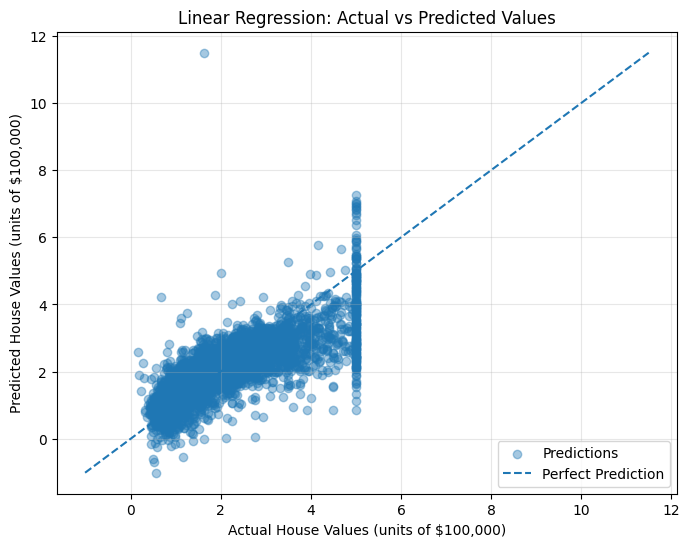

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4,
    label="Predictions"
)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual House Values (units of $100,000)")
plt.ylabel("Predicted House Values (units of $100,000)")
plt.title("Linear Regression: Actual vs Predicted Values")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
#Each point represents a test sample. Points close to the diagonal reference line indicate accurate predictions, while points farther from the line indicate larger errors. This visualization helps identify how closely the predicted values match the actual values.

**task 14 model performance report**


The Linear Regression model was trained using 80% of the California Housing dataset and evaluated on the remaining 20%. The model achieved a Mean Absolute Error (MAE) of **0.5332**, which means its predictions differ from the actual median house values by approximately **$53,320 on average**. The Root Mean Squared Error (RMSE) was **0.7456**, equivalent to approximately **$74,560**, indicating that prediction errors are relatively substantial, with larger errors having a greater impact on this metric. The R² score was **0.5758**, meaning that the model explains approximately **57.58% of the variation** in median house values in the test dataset. Overall, the model captures some important relationships in the housing data, but its performance could be improved by using more advanced models or capturing nonlinear relationships between the features and house values.